In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.io.arff import loadarff



In [14]:
# Load dataset and filter to only the columns we care about
movies = pd.read_csv("HollywoodMovies.csv")
cols = ["RottenTomatoes", "AudienceScore", "WorldwideBO", "Budget"]
print(movies.shape)
movies[["Movie"] + cols].head()

(844, 18)


,Movie,RottenTomatoes,AudienceScore,WorldwideBO,Budget
0,Avengers: Endgame,94.0,90.0,2748.24,400.0
1,The Lion King,51.0,88.0,1661.45,260.0
2,Star Wars: The Rise of Skywalker,51.0,86.0,1069.95,275.0
3,Frozen II,77.0,92.0,1451.65,150.0
4,Toy Story 4,97.0,94.0,1071.18,200.0


In [15]:
summary = pd.DataFrame({
    "non-missing": movies[cols].notna().sum(),
    "missing": movies[cols].isna().sum(),
    "mean": movies[cols].mean(),
    "median": movies[cols].median(),
    "SD": movies[cols].std(),
    "min": movies[cols].min(),
    "max": movies[cols].max(),
})
summary.round(2)

,non-missing,missing,mean,median,SD,min,max
RottenTomatoes,781,63,67.40,74.00,24.48,0.00,100.00
AudienceScore,824,20,76.99,81.00,17.70,7.00,100.00
WorldwideBO,688,156,111.68,18.35,261.11,0.11,2748.24
Budget,379,465,66.10,38.00,72.43,0.07,400.00


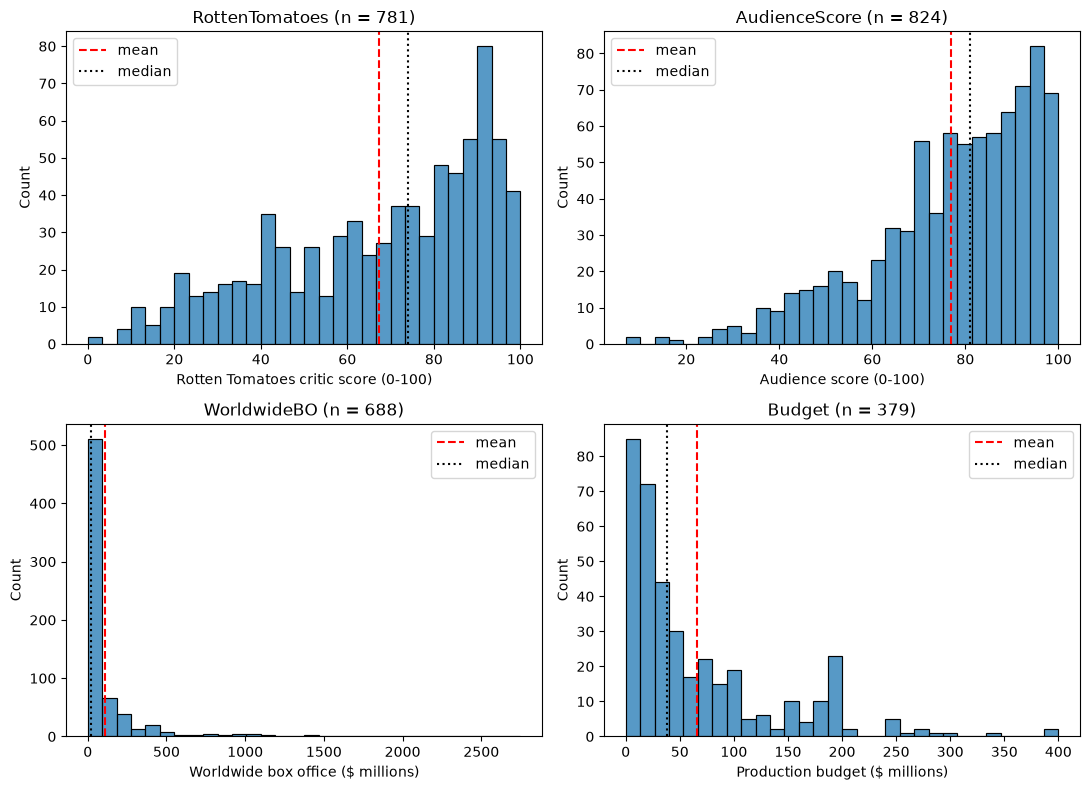

In [16]:
labels = {
    "RottenTomatoes": "Rotten Tomatoes critic score (0-100)",
    "AudienceScore": "Audience score (0-100)",
    "WorldwideBO": "Worldwide box office ($ millions)",
    "Budget": "Production budget ($ millions)",
}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, cols):
    sns.histplot(movies[col].dropna(), bins=30, ax=ax)
    ax.axvline(movies[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(movies[col].median(), color="black", linestyle=":", label="median")
    ax.set_xlabel(labels[col])
    ax.set_title(f"{col} (n = {movies[col].notna().sum()})")
    ax.legend()
plt.tight_layout()
plt.show()

The two scores are spread across the whole 0-100 range (critic scores are more spread out, audience scores lean high). Worldwide box office and budget are both strongly right-skewed.

## Missing and impossible values

In [17]:
# Impossible values: scores outside 0-100, or box office / budget that are zero or negative
impossible = {
    "RottenTomatoes": ~movies["RottenTomatoes"].between(0, 100) & movies["RottenTomatoes"].notna(),
    "AudienceScore": ~movies["AudienceScore"].between(0, 100) & movies["AudienceScore"].notna(),
    "WorldwideBO": movies["WorldwideBO"] <= 0,
    "Budget": movies["Budget"] <= 0,
}
pd.DataFrame({
    "missing": movies[cols].isna().sum(),
    "impossible": pd.Series({c: m.sum() for c, m in impossible.items()}),
})

,missing,impossible
RottenTomatoes,63,0
AudienceScore,20,0
WorldwideBO,156,0
Budget,465,0


In [ ]:
# Keep only movies that have every variable we need, with possible values
bad = pd.concat(impossible, axis=1).any(axis=1)
clean = movies[movies[cols].notna().all(axis=1) & ~bad].copy()
clean["Profit"] = clean["WorldwideBO"] / clean["Budget"]
print("Rows in original data:", len(movies))
print("Rows dropped:", len(movies) - len(clean))
print("Rows used in the analysis:", len(clean))

Rows in original data: 844
Rows dropped: 477
Rows used in the analysis: 367


**What was dropped.** No values were impossible (every score is between 0 and 100, and every box office and budget figure is positive; a few very small budgets such as *The Wretched* at $0.07M are real micro-budget films, and critic scores of 0 are real ratings). The drops are all from missing values, and Budget is by far the biggest cause: about 465 of the 844 films have no reported budget, which is common for small releases and streaming titles. So the analysis covers only films with a known budget and box office, which skews it toward larger, wider releases. Profitability is computed as WorldwideBO / Budget (1 = broke even), rather than using the provided Profitability column, so it is consistent with the variables listed above.

## Critic and audience scores vs. profitability

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, col in zip(axes, ["RottenTomatoes", "AudienceScore"]):
    sns.regplot(data=clean, x=col, y=np.log10(clean["Profit"]), ax=ax,
                scatter_kws={"alpha": 0.5, "s": 20}, line_kws={"color": "red"})
    ax.axhline(0, color="gray", linestyle=":")
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Profitability, log10(WorldwideBO / Budget)")
    r, p = stats.pearsonr(clean[col], np.log10(clean["Profit"]))
    ax.set_title(f"{col}: r = {r:.2f} (p = {p:.3g}, n = {len(clean)})")
plt.tight_layout()
plt.show()

A log10 value of 0 means the film earned back exactly its budget, 1 means it earned 10x its budget, and -1 means it earned only a tenth of it. The red line is the least-squares fit and *r* is the correlation between the score and log profitability.

## Group sizes and related rows

In [ ]:
print("Movies per year (clean data):")
print(clean["Year"].value_counts().sort_index())
print()
print("Movies per genre (clean data):")
print(clean["Genre"].value_counts())

In [ ]:
# Duplicate titles: the same title appearing more than once
dupes = movies[movies["Movie"].duplicated(keep=False)]
dupes[["Movie", "Year", "Distributor", "Genre", "RottenTomatoes", "WorldwideBO", "Budget"]]

In [ ]:
# Likely sequels / franchise entries: titles ending in a number, or containing "Part" or "Chapter"
sequel = movies["Movie"].str.contains(r"(?:\s\d+$|\s\d+:|Part|Chapter|II|III)", regex=True)
print("Likely sequels in full data:", sequel.sum())
print("Likely sequels in clean data:", sequel[clean.index].sum())
movies.loc[sequel, ["Movie", "Year"]].sort_values("Movie")

The two films titled *Memory* (2022 and 2023) are different movies that share a name, not duplicate rows, so both are kept (the 2022 one has no budget and drops out anyway). Sequels are related to their earlier films (same franchise, built-in audience), so they are not fully independent observations; they are kept in, but they are worth keeping in mind because franchise films tend to have large budgets and box office regardless of reviews.